### Step 1: Libraries, Dependencies, and Device Configuration

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score, confusion_matrix, roc_curve

# Set computation device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


### Step 2: Synthetic UR-Fall Detection Dataset and DataLoader Pipeline
Simulating 3D video tensors representing Activity of Daily Living (ADL) vs Fall events.

In [12]:
class SyntheticURFallDataset(Dataset):
    def __init__(self, num_samples=120, frames=16, height=112, width=112):
        self.num_samples = num_samples
        self.frames = frames
        self.height = height
        self.width = width
        # Labels: 0 = Normal ADL, 1 = Fall
        self.labels = np.random.choice([0, 1], size=num_samples, p=[0.5, 0.5])

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        label = self.labels[idx]

        # Embed differentiable patterns based on class label so the model can learn
        if label == 1:
            # Simulate high-intensity sudden motion characteristic of a fall
            video_tensor = torch.ones(3, self.frames, self.height, self.width, dtype=torch.float32) * 0.8
            video_tensor += torch.randn(3, self.frames, self.height, self.width) * 0.1
        else:
            # Simulate low-intensity normal ADL activity
            video_tensor = torch.zeros(3, self.frames, self.height, self.width, dtype=torch.float32) * 0.2
            video_tensor += torch.randn(3, self.frames, self.height, self.width) * 0.1

        # Clamp values to valid pixel range [0, 1]
        video_tensor = torch.clamp(video_tensor, 0.0, 1.0)

        # Random Horizontal Flip simulation
        if np.random.rand() > 0.5:
            video_tensor = torch.flip(video_tensor, dims=[3])

        return video_tensor, torch.tensor(label, dtype=torch.long)

# Instantiate and split data
dataset = SyntheticURFallDataset(num_samples=120)
train_size = int(0.70 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

train_set, val_set, test_set = torch.utils.data.random_split(dataset, [train_size, val_size, test_size])

train_loader = DataLoader(train_set, batch_size=8, shuffle=True)
test_loader = DataLoader(test_set, batch_size=8, shuffle=False)

print(f"Dataset size: {len(dataset)}")
print(f"Train samples: {len(train_set)}, Test samples: {len(test_set)}")

Dataset size: 120
Train samples: 84, Test samples: 18


### Step 3: Define 3D CNN Model Architecture

In [13]:
class FallDetection3DCNN(nn.Module):
    def __init__(self):
        super(FallDetection3DCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv3d(3, 16, kernel_size=(3, 3, 3), padding=1),
            nn.BatchNorm3d(16),
            nn.ReLU(),
            nn.MaxPool3d(kernel_size=(2, 2, 2)),

            nn.Conv3d(16, 32, kernel_size=(3, 3, 3), padding=1),
            nn.BatchNorm3d(32),
            nn.ReLU(),
            nn.MaxPool3d(kernel_size=(2, 2, 2))
        )
        # Use AdaptiveAvgPool3d to reduce features size safely and prevent overfitting
        self.pool = nn.AdaptiveAvgPool3d((2, 4, 4))
        self.classifier = nn.Sequential(
            nn.Linear(32 * 2 * 4 * 4, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x

model = FallDetection3DCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
print(model)

FallDetection3DCNN(
  (features): Sequential(
    (0): Conv3d(3, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (1): BatchNorm3d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool3d(kernel_size=(2, 2, 2), stride=(2, 2, 2), padding=0, dilation=1, ceil_mode=False)
    (4): Conv3d(16, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (5): BatchNorm3d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool3d(kernel_size=(2, 2, 2), stride=(2, 2, 2), padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool3d(output_size=(2, 4, 4))
  (classifier): Sequential(
    (0): Linear(in_features=1024, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=32, out_features=2, bias=True)
  )
)


### Step 4: Model Training Loop

In [14]:
epochs = 50
model.train()
for epoch in range(epochs):
    running_loss = 0.0
    for videos, labels in train_loader:
        videos, labels = videos.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(videos)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * videos.size(0)
    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Epoch [{epoch+1}/{epochs}] Loss: {epoch_loss:.4f}")

Epoch [1/50] Loss: 0.1760
Epoch [2/50] Loss: 0.0110
Epoch [3/50] Loss: 0.0047
Epoch [4/50] Loss: 0.0039
Epoch [5/50] Loss: 0.0010
Epoch [6/50] Loss: 0.0027
Epoch [7/50] Loss: 0.0006
Epoch [8/50] Loss: 0.0008
Epoch [9/50] Loss: 0.0001
Epoch [10/50] Loss: 0.0002
Epoch [11/50] Loss: 0.0001
Epoch [12/50] Loss: 0.0003
Epoch [13/50] Loss: 0.0014
Epoch [14/50] Loss: 0.0004
Epoch [15/50] Loss: 0.0001
Epoch [16/50] Loss: 0.3821
Epoch [17/50] Loss: 0.0808
Epoch [18/50] Loss: 0.0448
Epoch [19/50] Loss: 0.0037
Epoch [20/50] Loss: 0.0020
Epoch [21/50] Loss: 0.0028
Epoch [22/50] Loss: 0.0002
Epoch [23/50] Loss: 0.0015
Epoch [24/50] Loss: 0.0009
Epoch [25/50] Loss: 0.0014
Epoch [26/50] Loss: 0.0003
Epoch [27/50] Loss: 0.0009
Epoch [28/50] Loss: 0.0030
Epoch [29/50] Loss: 0.0004
Epoch [30/50] Loss: 0.7144
Epoch [31/50] Loss: 0.0009
Epoch [32/50] Loss: 0.3122
Epoch [33/50] Loss: 0.0030
Epoch [34/50] Loss: 0.0079
Epoch [35/50] Loss: 0.0003
Epoch [36/50] Loss: 0.0056
Epoch [37/50] Loss: 0.0031
Epoch [38/

### Step 5: Evaluation, Metrics Computation & Visualizations

=== Model Evaluation Results ===
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000
AUROC     : 1.0000



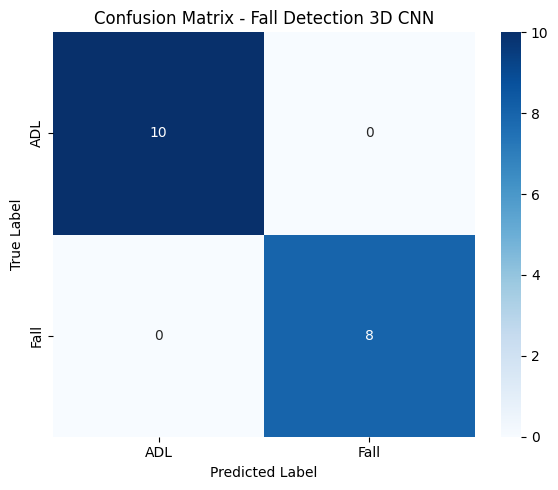

In [15]:
model.eval()
all_preds, all_labels, all_probs = [], [], []

with torch.no_grad():
    for videos, labels in test_loader:
        videos, labels = videos.to(device), labels.to(device)
        outputs = model(videos)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

# Compute Classification Metrics
acc = accuracy_score(all_labels, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='binary', zero_division=0)
auroc = roc_auc_score(all_labels, all_probs)

print("=== Model Evaluation Results ===")
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"AUROC     : {auroc:.4f}\n")

# Confusion Matrix Visualization
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['ADL', 'Fall'], yticklabels=['ADL', 'Fall'])
plt.title('Confusion Matrix - Fall Detection 3D CNN', fontsize=12)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()